<a href="https://colab.research.google.com/github/OscarGalloGarcia/Msc-artificial-neural-networks/blob/main/P3_Red_Nuronal_Multicapa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practica 3: Red Neuronal Multicapa

Oscar Alberto Gallo García
Msc en Robótica e Inteligencia Artificial



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Clase Red Neuronal Multicapa

In [2]:
# Funcion softmax
def softmax(z):
  e = np.exp(z - np.max(z, axis=0))
  a = e / np.sum(e, axis=0)
  da = a * (1 - a)
  return a, da

In [22]:
class MLP:
  def __init__(self, l_layers, n_inputs, learning_rate, shuffle):
    self.L = len(l_layers) - 1 # numero de capas
    self.n_inputs = n_inputs # numero de entradas

    self.w = [None] * (self.L + 1) #pesos
    self.b = [None] * (self.L + 1) #bias
    self.f = [None] * (self.L + 1) #funcion de activacion
    self.layers = l_layers
    self.learning_rate = learning_rate # eta -> learning rate
    self.shuffle = shuffle #mezclar patrones al inicio

    self.error = []


    #inicializar
    for l in range(1, self.L + 1):
      self.w[l] = -1 + 2 * np.random.rand(l_layers[l], l_layers[l - 1])
      self.b[l] = -1 + 2 * np.random.rand(l_layers[l], 1)
      self.f[l] = self.sigmoid # Inicializando con la funcion sigmoide todas las nuronas

  # Funcion de activacion
  def sigmoid(self, v):
    a = 1 / (1 + np.exp(-v))
    da = a * (1 - a)
    return a, da


  def net_input(self, X):
    return np.dot(X, self.w) + self.b # v

  def train(self, X, Y, epochs):
    n_samples = X.shape[1] # número de muestras
    #Gradiente descendente

    self.error = []
    for _ in range(epochs):
      suma_error_epoca = 0
      for p in range(n_samples):
        # Instanciando variables necesarias
        a = [None] * (self.L + 1)
        da = [None] * (self.L + 1)
        local_gradient = [None] * (self.L + 1)

        A = [None] * (self.L + 1)


        # Forward propagation
        A[0] = X[:,p].reshape(-1, 1)
        for l in range(1, self.L + 1):
          z = np.dot(self.w[l], A[l - 1]) + self.b[l]
          a[l], da[l] = self.sigmoid(z)
          A[l] = a[l]

        # Backpropagation
        for l in range(self.L, 0, -1):
          if l == self.L:
            # Gradiente local de la capa de salida
            #local_gradient[l] = -(Y - a[l]) * da[l]
            local_gradient[l] = (Y[:, p].reshape(4, 1) - a[l]) * da[l]
          else:
            # Gradiente local de capas ocultas
            local_gradient[l] = np.dot(self.w[l + 1].T, local_gradient[l + 1]) * da[l]

        #Gradiente desendente
        for l in range(1, self.L + 1):
          self.w[l] += self.learning_rate * np.dot(local_gradient[l], A[l - 1].T)
          self.b[l] += self.learning_rate * local_gradient[l]

        e_p = Y[:, p].reshape(4, 1) - a[self.L]# Error de cada patron
        suma_error_epoca += np.sum(e_p ** 2) * 0.5

      Eav = suma_error_epoca / n_samples
      self.error.append(Eav)

  def predict(self, X):
    # Forward propagation to predict outputs
    a = np.asanyarray(X)
    for l in range(1, self.L + 1): #Desde la capa 1 hasta la ultima
      z = np.dot(self.w[l], a) + self.b[l]
      a = self.f[l](z)[0]
    return a

Ingesta de datos

In [4]:
!wget 'https://github.com/OscarGalloGarcia/Msc-artificial-neural-networks/raw/main/datasets/ensaantro2022_entrega_w.csv.csv/ensaantro2022_entrega_w.csv'



--2026-10-26 05:04:22--  https://github.com/OscarGalloGarcia/Msc-artificial-neural-networks/raw/main/datasets/ensaantro2022_entrega_w.csv.csv/ensaantro2022_entrega_w.csv
Resolving github.com (github.com)... 140.82.112.3
Connecting to github.com (github.com)|140.82.112.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/OscarGalloGarcia/Msc-artificial-neural-networks/main/datasets/ensaantro2022_entrega_w.csv.csv/ensaantro2022_entrega_w.csv [following]
--2026-10-26 05:04:22--  https://raw.githubusercontent.com/OscarGalloGarcia/Msc-artificial-neural-networks/main/datasets/ensaantro2022_entrega_w.csv.csv/ensaantro2022_entrega_w.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5818250 (5.5M) [text/

Lectura de datos

In [5]:
dataset = pd.read_csv('ensaantro2022_entrega_w.csv')
dataset.head()

,FOLIO_I,FOLIO_INT,t_hora,t_min,t_sumai,t_sumaf,hora_ini_1,fecha_ini_1,hora_fin_1,fecha_fin_1,...,comentario,tiempo,hora_fin,fecha_fin,completa,otroent,ponde_f,estrato,est_sel,upm
0,2022_01001001,2022_01001001_01,20,31,1228,1231,20:28:39,09/11/2022,20:31:33,09/11/2022,...,,3,20:31:33,09/11/2022,1,,999.761286,3,13,0100100011320
1,2022_01001001,2022_01001001_02,20,28,1226,1228,20:26:30,09/11/2022,20:28:37,09/11/2022,...,,2,20:28:37,09/11/2022,1,,1546.785919,3,13,0100100011320
2,2022_01001003,2022_01001003_02,20,36,1231,1236,20:31:35,09/11/2022,20:36:37,09/11/2022,...,,5,20:36:37,09/11/2022,1,,2926.133592,3,13,0100100011320
3,2022_01001003,2022_01001003_03,19,29,1080,1169,18:00:46,10/11/2022,19:29:56,10/11/2022,...,"ta correcta de la 3° es de 89/43 , se coloca 8...",89,19:29:56,10/11/2022,1,,1819.859020,3,13,0100100011320
4,2022_01001003,2022_01001003_06,20,37,1236,1237,20:36:38,09/11/2022,20:37:59,09/11/2022,...,,1,20:37:59,09/11/2022,1,,4640.357758,3,13,0100100011320


In [6]:
# Total de columnas:
num_columnas_len = len(dataset.columns)
print(f"Número de columnas: {num_columnas_len}")

Número de columnas: 98


In [7]:
dataset[['an01_1', 'an04_1', 'h0303']].dtypes

,0
an01_1,object
an04_1,object
h0303,int64


In [8]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15073 entries, 0 to 15072
Data columns (total 98 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   FOLIO_I      15073 non-null  object 
 1   FOLIO_INT    15073 non-null  object 
 2   t_hora       15073 non-null  int64  
 3   t_min        15073 non-null  int64  
 4   t_sumai      15073 non-null  int64  
 5   t_sumaf      15073 non-null  int64  
 6   hora_ini_1   15073 non-null  object 
 7   fecha_ini_1  15073 non-null  object 
 8   hora_fin_1   15073 non-null  object 
 9   fecha_fin_1  15073 non-null  object 
 10  tiempo1      15073 non-null  int64  
 11  resultado_1  15073 non-null  int64  
 12  hora_ini_2   15073 non-null  object 
 13  fecha_ini_2  15073 non-null  object 
 14  hora_fin_2   15073 non-null  object 
 15  fecha_fin_2  15073 non-null  object 
 16  tiempo2      15073 non-null  int64  
 17  resultado_2  15073 non-null  int64  
 18  hora_ini_3   15073 non-null  object 
 19  fech

In [9]:
#Hacer una copia del dataset que sera con el que voy a trabajar
df = dataset.copy()

Limpieza de datos

In [10]:
# Las columnas de peso y estatura estan revueltas con nomenclaturas extrañas
# Lo primero es crear columnas limpias que tengan esa data

#       Edad     embarazo  peso     estatura
cols = ['h0303', 'an06', 'an01_1', 'an04_1']
# Hacerlos numericos
df = df[cols].apply(pd.to_numeric, errors='coerce')

datos = df[
      df['an01_1'].between(2, 250)   # peso válido (quitando 222.22)
    & df['an04_1'].between(40, 230)  # estatura válida (quitando 222.20)
    & df['h0303'].between(20, 110)   # edad -> adultos
    & ~df['an06'].isin([1, 2, 3])    # sin embarazo ni lactancia
].copy()

datos['altura'] = datos['an04_1'] / 100 #metros
datos['peso']   = datos['an01_1']   # Kg



Calcular salida deseada a partir de la formula de IMC

In [11]:
# Formula IMC
datos['imc']    = datos['peso'] / datos['altura'] ** 2
datos['d']      = np.where(datos['imc'] >= 25, 1, -1)

Preparando la Clasificacion con las 4 clases

In [12]:
# crear la categoría
c1 = (datos['imc'] >= 0) & (datos['imc'] < 18.5) # Peso bajo
c2 = (datos['imc'] >= 18.5) & (datos['imc'] < 25) # Peso Normal
c3 = (datos['imc'] >= 25) & (datos['imc'] < 30) # Sobre peso
c4 = (datos['imc'] >= 30)   # obesidad

In [13]:
#one shot encodig
datos['C1'] = c1.astype(np.float32)
datos['C2'] = c2.astype(np.float32)
datos['C3'] = c3.astype(np.float32)
datos['C4'] = c4.astype(np.float32)


In [14]:
datos = datos[['altura', 'peso', 'imc', 'C1', 'C2', 'C3', 'C4']].reset_index(drop=True)
datos.head()

,altura,peso,imc,C1,C2,C3,C4
0,1.416,69.30,34.562626,0.0,0.0,0.0,1.0
1,1.568,110.35,44.882829,0.0,0.0,0.0,1.0
2,1.773,104.40,33.211082,0.0,0.0,0.0,1.0
3,1.664,77.00,27.808917,0.0,0.0,1.0,0.0
4,1.734,81.50,27.105625,0.0,0.0,1.0,0.0


Entrada y salida

In [15]:
# Extraer las características (altura y peso)
x_raw = np.asanyarray(datos.drop(columns=['imc', 'C1', 'C2', 'C3', 'C4']))

# Estandarizar x
mean = x_raw.mean(axis=0)
std = x_raw.std(axis=0)

# Definir la entrada de la red (peso y altura)
x = (x_raw - mean) / std

# Definir la salida deseada (en este caso seran las 4 categorias)
y = np.asanyarray(datos[['C1', 'C2', 'C3', 'C4']])



Particionar el dataset 70% train, 20% test

In [23]:
train = datos.sample(frac=0.8, random_state=42)
test = datos.drop(train.index)

Crear instancia de la red neuronal multicapa (MLP)

In [24]:
_, n_inputs = x.shape

In [25]:
np.random.seed(42) #semilla para la inicializacion de pesos

#Arquitectura de red
# entradas, capa oculta, capa salida
l = [2, 6, 4]

net = MLP(l_layers=l, n_inputs=n_inputs,
            learning_rate=0.01,
            shuffle=True)

In [26]:
net.w[1]

x.shape

(6246, 2)

Entrenamiento

In [27]:
net.train(X=x.T, Y=y.T, epochs=200)

Error por epoca

El entrenamiento finalizó en 200 épocas.
MSE inicial: 0.3155
MSE final: 0.0247


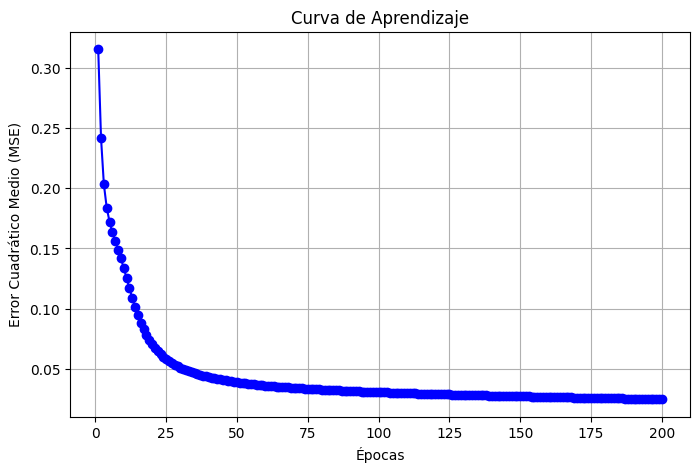

In [28]:
print(f"El entrenamiento finalizó en {len(net.error)} épocas.")
print(f"MSE inicial: {net.error[0]:.4f}")
print(f"MSE final: {net.error[-1]:.4f}")

# Graficar la curva del MSE para verificar la convergencia
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(net.error) + 1), net.error, marker='o', color='b')
plt.xlabel('Épocas')
plt.ylabel('Error Cuadrático Medio (MSE)')
plt.title('Curva de Aprendizaje')
plt.grid(True)
plt.show()

Evaluacion

In [29]:
#Utilizando el conjunto que dejamos para el test
x_test_raw = np.asanyarray(test[['altura', 'peso']])
x_test = (x_test_raw - mean) / std

y_test = np.asanyarray(test[['C1', 'C2', 'C3', 'C4']])

y_pred = net.predict(x_test.T)

# Como y_pred retorna probabilidades continuas, podemos redondear o usar argmax
# para obtener la clase predicha y calcular la exactitud (accuracy)
y_pred_class = np.argmax(y_pred, axis=0)
y_test_class = np.argmax(y_test, axis=1)

# Calculo del accuracy
accuracy = np.mean(y_pred_class == y_test_class)
print(f"Accuracy en el conjunto de prueba: {accuracy * 100:.2f}%")


Accuracy en el conjunto de prueba: 97.28%


Matriz de confusión

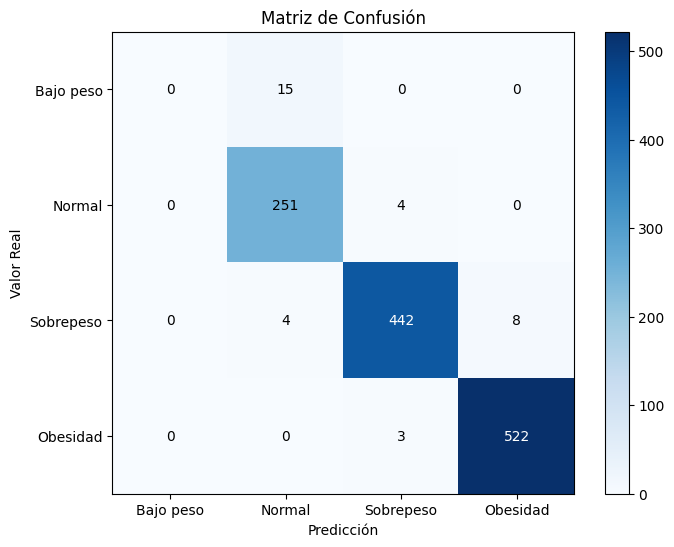

In [30]:
# Calcular la matriz de confusión desde cero
num_classes = 4
cm = np.zeros((num_classes, num_classes), dtype=int)

for true_label, pred_label in zip(y_test_class, y_pred_class):
    cm[true_label, pred_label] += 1

# Nombres de las clases para la visualización
class_names = ['Bajo peso', 'Normal', 'Sobrepeso', 'Obesidad']

# Graficar usando solo matplotlib
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(cm, cmap='Blues')
fig.colorbar(cax)

# Configurar ejes
ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

# Ajustar las etiquetas al eje inferior
ax.xaxis.set_ticks_position('bottom')

plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')

# Agregar los valores numéricos en cada celda
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, str(cm[i, j]), va='center', ha='center',
                color="white" if cm[i, j] > cm.max()/2 else "black")

plt.show()

Mapa de regiones de desicion

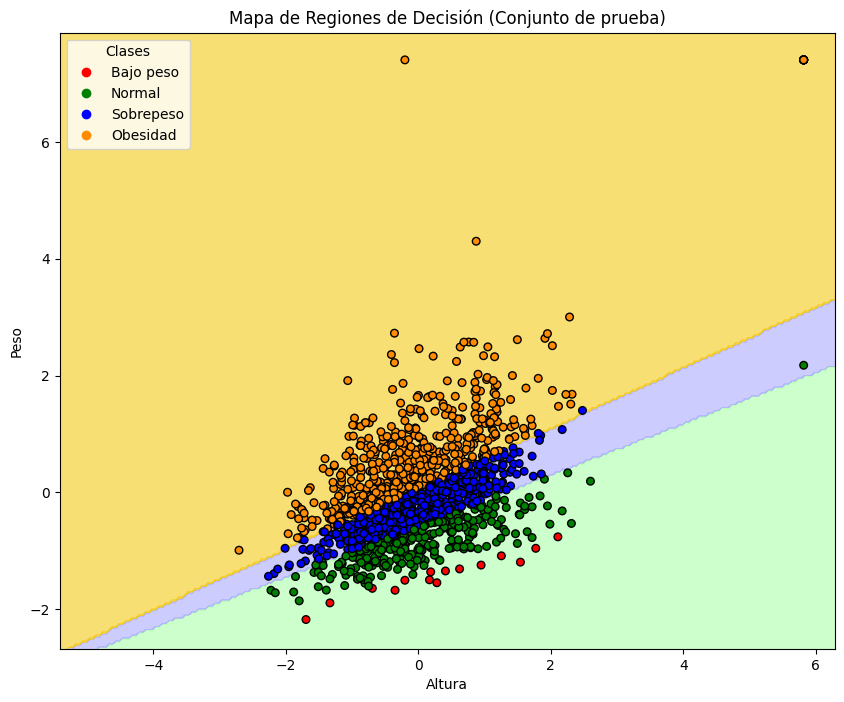

In [31]:
from matplotlib.colors import ListedColormap

# Crear una malla (meshgrid) para evaluar el modelo en todo el espacio
x_min, x_max = x[:, 0].min() - 0.5, x[:, 0].max() + 0.5
y_min, y_max = x[:, 1].min() - 0.5, x[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

grid_points = np.c_[xx.ravel(), yy.ravel()]

# Realizar predicciones sobre la malla
Z_prob = net.predict(grid_points.T)
Z = np.argmax(Z_prob, axis=0)
Z = Z.reshape(xx.shape)

# Colores para el mapa y los puntos
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#F4CA16'])
cmap_bold = ListedColormap(['#FF0000', '#008000', '#0000FF', '#FF8C00'])

plt.figure(figsize=(10, 8))
# Dibujar las fronteras de decisión forzando la escala de 0 a 3
plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.6, vmin=0, vmax=3)

# Dibujar los puntos del conjunto de prueba para ver cómo caen en las regiones
scatter = plt.scatter(x_test[:, 0], x_test[:, 1], c=y_test_class, cmap=cmap_bold, edgecolor='k', s=30, vmin=0, vmax=3)

plt.xlabel('Altura')
plt.ylabel('Peso')
plt.title('Mapa de Regiones de Decisión (Conjunto de prueba)')

legend_labels = ['Bajo peso', 'Normal', 'Sobrepeso', 'Obesidad']
handles, _ = scatter.legend_elements()
plt.legend(handles, legend_labels, title='Clases')

plt.show()

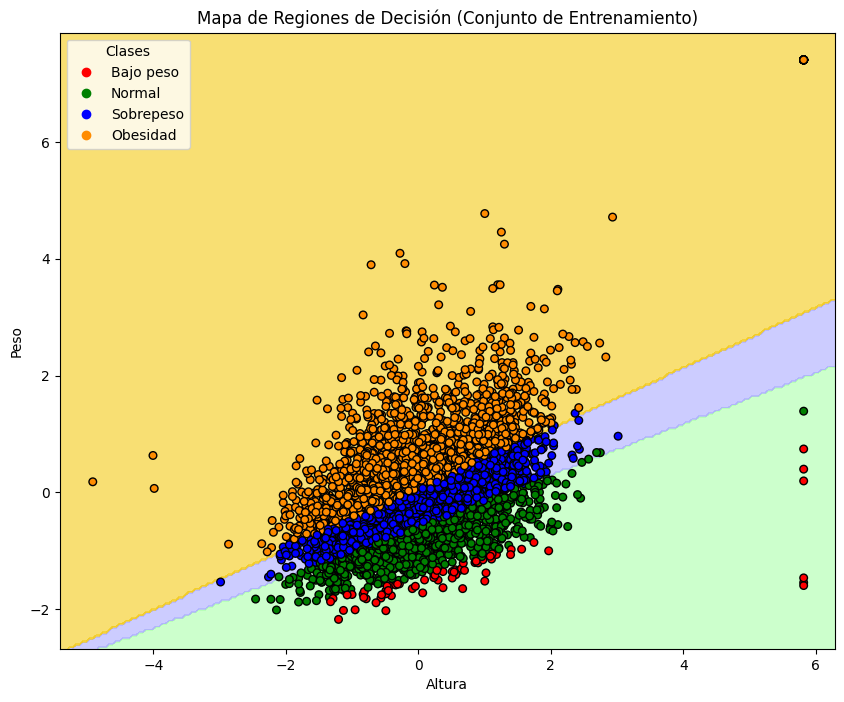

In [32]:
# Extraer y estandarizar datos de entrenamiento
x_train_raw = np.asanyarray(train[['altura', 'peso']])
x_train = (x_train_raw - mean) / std

y_train = np.asanyarray(train[['C1', 'C2', 'C3', 'C4']])
y_train_class = np.argmax(y_train, axis=1)

plt.figure(figsize=(10, 8))
# Dibujar las fronteras de decisión forzando la escala de 0 a 3 (usamos la malla calculada anteriormente)
plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.6, vmin=0, vmax=3)

# Dibujar los puntos del conjunto de entrenamiento
scatter_train = plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train_class, cmap=cmap_bold, edgecolor='k', s=30, vmin=0, vmax=3)

plt.xlabel('Altura')
plt.ylabel('Peso')
plt.title('Mapa de Regiones de Decisión (Conjunto de Entrenamiento)')

legend_labels = ['Bajo peso', 'Normal', 'Sobrepeso', 'Obesidad']
handles_train, _ = scatter_train.legend_elements()
plt.legend(handles_train, legend_labels, title='Clases')

plt.show()